In [23]:
pip install tensorflow streamlit pillow numpy scikit-learn

In [31]:
import os

TRAIN_DIR = "dataset/train"

for root, dirs, files in os.walk(TRAIN_DIR):
    print("Folder:", root)
    print("Images:", [
        f for f in files
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".gif")
        )
    ])

Folder: dataset/train
Images: []


In [41]:
from google.colab import files

uploaded = files.upload()

Saving images.jpg to images (1).jpg


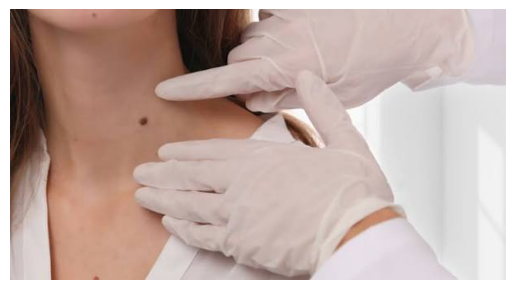

In [42]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open("images.jpg").convert("RGB")

plt.imshow(image)
plt.axis("off")
plt.show()

Saving images.jpg to images (2).jpg


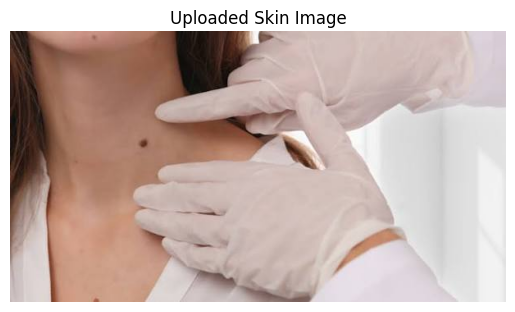

Image uploaded successfully!
Image size: (605, 330)


In [43]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

image = Image.open(image_path).convert("RGB")

plt.imshow(image)
plt.title("Uploaded Skin Image")
plt.axis("off")
plt.show()

print("Image uploaded successfully!")
print("Image size:", image.size)

In [44]:
import numpy as np

IMG_SIZE = (224, 224)

resized_image = image.resize(IMG_SIZE)

image_array = np.array(
    resized_image,
    dtype=np.float32
)

image_array = np.expand_dims(image_array, axis=0)

print("Image shape:", image_array.shape)

Image shape: (1, 224, 224, 3)


In [49]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "\HAM10000_metadata.csv\skin_disease_model.keras"
)

with open("/content/class_names.txt", "r") as file:
    class_names = [
        line.strip()
        for line in file
        if line.strip()
    ]

print("Model loaded successfully!")
print("Disease classes:", class_names)

<>:4: SyntaxWarning: invalid escape sequence '\H'
<>:4: SyntaxWarning: invalid escape sequence '\H'
/tmp/ipykernel_2029/2524566655.py:4: SyntaxWarning: invalid escape sequence '\H'
  "\HAM10000_metadata.csv\skin_disease_model.keras"


ValueError: File not found: filepath=\HAM10000_metadata.csv\skin_disease_model.keras. Please ensure the file is an accessible `.keras` zip file.

In [47]:
predictions = model.predict(image_array, verbose=0)[0]

predicted_index = int(np.argmax(predictions))
predicted_class = class_names[predicted_index]
confidence = float(predictions[predicted_index]) * 100

print("Predicted class:", predicted_class)
print(f"Model score: {confidence:.2f}%")


NameError: name 'model' is not defined